# Bioreactor case study: closed loop of one seed

This notebook reproduces the closed-loop figure of the case study of the paper: one run of
every method on seed 11 of the Monte Carlo study (`montecarlo_bioreactor.ipynb`), with the benchmark defined in
`config/bioreactor.yaml`.

1. [The bioreactor](#1.-The-bioreactor): plant, model, control problem, methods
2. [Parameters](#2.-Parameters)
3. [Closed-loop runs](#3.-Closed-loop-runs)
4. [Paper figure](#4.-Paper-figure)
5. [Ablation: ω = 0](#5.-Ablation:-ω-=-0)

**Running.** Use the project's virtual environment as the kernel (`pip install -e ".[notebook]"`). The runs are saved in
`results/bioreactor_runs/<configuration fingerprint>/` together with the configuration, and are loaded from there when the
notebook runs again with the same configuration.

## 1. The bioreactor

### Plant

A continuous stirred bioreactor with biomass $X$, substrate $S$ and product $P$ (g/L), controlled by the dilution rate $D$
(1/h):

$$
\begin{aligned}
\dot X &= \mu X - k_{dp} P X - D X, \\
\dot S &= -\frac{\mu X}{Y_{xs}} + D\,(S_f - S), \\
\dot P &= (Y_{px}\,\mu + \beta)\,X - D P,
\end{aligned}
\qquad
\mu(S, P, t) = \eta(t)\,\mu_{\max}\,\frac{S}{K_s + S + S^2/K_i}\Big(1 - \frac{P}{P_{\max}}\Big)_+ .
$$

The specific growth rate $\mu$ follows Haldane kinetics (substrate inhibition) with product inhibition. It peaks at
$S^* = \sqrt{K_s K_i}$; the plant operates at substrate levels above $S^*$, where $\mu$ decreases with $S$. Raising $D$ raises
$S$ and lowers $\mu$, so beyond a critical dilution rate the biomass can no longer sustain itself and is washed out.

The mixing efficiency $\eta(t)$ is unknown to the controller and drops during the run,

$$
\eta(t) = \eta_{\mathrm{start}} + \frac{\eta_{\mathrm{end}} - \eta_{\mathrm{start}}}{1 + e^{-(t - t_c)/w}},
$$

which lowers the growth rate and moves the washout boundary to lower dilution rates.

The plant is sampled every $t_s$ hours, with $D$ held constant between samples (zero-order hold) and the balances
integrated by $n_{\mathrm{sub}}$ Runge-Kutta (RK4) substeps per sample. Only the product is measured:

$$
x_{t+1} = F(x_t, D_t, t) + q_t, \quad q_t \sim \mathcal N(0, Q_{\mathrm{true}}), \qquad
y_t = P_t + r_t, \quad r_t \sim \mathcal N(0, R_{\mathrm{true}}),
$$

with $x = (X, S, P)$ and $F$ the RK4 map over one sample. The plant starts at the steady state of the first reference.

### Model

The controller uses the gray-box model eq:model in normalized coordinates, $x = \Lambda_x^{-1}(x^{\mathrm p} - \mu_x)$ and
$u = \Lambda_u^{-1}(D - \mu_u)$, with the constants set from the operating ranges. The mass balances above are known; the
growth rate is learned:

$$
\mu_\theta(S, P) = \mu_{\mathrm{scale}}\;\mathrm{softplus}\big(\mathrm{NN}(\tilde S, \tilde P;\, \theta)\big),
$$

a network with one hidden layer of tanh units on the normalized $\tilde S, \tilde P$. The mixing efficiency is not modelled
separately: its effect is absorbed by the network, whose weights $\theta$ are estimated online. The model $f(x, u, \theta)$ is
one RK4 step of the balances per sample. It starts from an untrained network whose output bias gives the steady growth rate
$\mu_0 = D_0 + k_{dp} P_0$ of the initial steady state (the biomass balance at the initial input $D_0$ and product $P_0$),
and the state estimate starts at that steady state, computed from the balances without knowledge of $\eta$.

**Physical laws.** The learned growth rate must respect substrate inhibition above $S^*$ and product inhibition,

$$
\frac{\partial \mu_\theta}{\partial S} \le 0, \qquad \frac{\partial \mu_\theta}{\partial P} \le 0,
$$

imposed on a grid of $(S, P)$ and at two moving points, the current state estimate and the end of the predicted trajectory.
The Stein filters impose them with the modified differential method of multipliers (MDMM) inside the update; RBPF rejects
the particles that violate them.

### Control problem

The product tracks a piecewise-constant reference $r_t$, and the biomass is kept in the corridor
$X_{\min} \le X \le X_{\max}$: the lower bound guards against washout, the upper bound represents the oxygen-transfer
capacity. These are two chance constraints of the form eq:cc-ideal,

$$
\Pr\big(X_{t+\ell} \ge X_{\min} \mid y_{1:t}, U_t\big) \ge 1 - \delta, \qquad
\Pr\big(X_{t+\ell} \le X_{\max} \mid y_{1:t}, U_t\big) \ge 1 - \delta, \qquad \ell = 1, \dots, L,
$$

imposed on the mixture of the particle scenarios (eq:cc-mixture) in the scenario SMPC eq:smpc, with
$D \in [D_{\min}, D_{\max}]$. Each constraint has a slack with a linear and a quadratic penalty, so the problem stays
feasible. The reference segments are chosen so that the constraints are active: the first drives $X$ towards $X_{\max}$ at full
mixing, the second spans the drop of $\eta$, and the third drives $X$ towards $X_{\min}$ after it (see the operating points
below).

### Methods

| method | filter | controller |
|---|---|---|
| `param` | RBSGD with the parameter kernel $k_\theta$ (eq:kernels) | scenario SMPC eq:smpc |
| `ca` | RBSGD with the control-aware kernel $k_\omega = k_\Phi + \omega k_\theta$, where $\Phi_t(\theta)$ collects the predicted outputs and constraint margins under the shifted plan (eq:feature-map) | scenario SMPC eq:smpc |
| `rbpf` | Rao-Blackwellized particle filter (random-walk proposal on $\theta$, one EKF per particle) | scenario SMPC with the particle weights |
| `ce` | the `ca` filter | certainty-equivalent MPC on the particle mean, no uncertainty |
| `ca0` | ablation: the `ca` filter with $\omega = 0$, i.e. $k_\Phi$ alone (Section 5) | scenario SMPC eq:smpc |

The Stein filters use the score eq:score with a Stein variational Newton step (`optimizer: svn`: the SVGD direction
eq:svgd-dir preconditioned by the kernel-averaged Gauss-Newton curvature of the posterior). Filters and controllers assume
the plant's noise covariances. For a given seed, every method sees the same noise realizations and starts from the same
particles.

In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from carbsgd.config import CONFIG_DIR, ROOT, load_config
from carbsgd.bioreactor import BioPlant
from carbsgd.bio_mc import run_cached
from carbsgd.bio_setup import bio_summary

## 2. Parameters

All values come from `config/bioreactor.yaml` (loaded on top of `config/default.yaml`). `overrides` changes them for an
experiment; `kernel_hp` holds the bandwidth scales of the kernels, at the values of the configuration file. The runs of a
changed configuration are saved under a new fingerprint (every method runs again once), and the runs of the paper's
setting stay available.

In [2]:
seed = 11                                   # the run shown in the paper (the Monte Carlo uses seeds 1-100)
methods = ["ce", "param", "ca", "ca0", "rbpf"]

# kernel bandwidths: h = scale x median heuristic (median of the squared pairwise distances / log N)
kernel_hp = {
    "scale_h_param": 1.0,                   # param: k_theta on the weights (larger: flatter kernel, weaker repulsion)
    "scale_h_phi": 0.02,                    # ca: k_Phi on the predicted outputs and margins
    "scale_h": 1.0,                         # ca: k_theta of the omega term
}
overrides = {"filter": kernel_hp}           # changes to the benchmark (the values above are the paper's setting)
cfg = load_config(CONFIG_DIR / "bioreactor.yaml", overrides=overrides)

In [3]:
b, fc, rc, mc = cfg["bio"], cfg["filter"], cfg["rbpf"], cfg["mpc"]
rows = [
    # plant
    ("plant", "μ_max", b["mu_max"], "1/h", "maximum specific growth rate"),
    ("plant", "K_s", b["Ks"], "g/L", "half-saturation constant"),
    ("plant", "K_i", b["Ki"], "g/L", "substrate-inhibition constant"),
    ("plant", "Y_xs", b["Yxs"], "-", "biomass yield on substrate"),
    ("plant", "Y_px", b["Ypx"], "-", "growth-associated product yield"),
    ("plant", "β", b["beta"], "1/h", "non-growth-associated product formation"),
    ("plant", "k_dp", b["kdp"], "L/(g h)", "product-induced biomass death"),
    ("plant", "S_f", b["Sf"], "g/L", "feed substrate concentration"),
    ("plant", "P_max", b["Pmax"], "g/L", "product concentration that stops growth"),
    ("plant", "η_start → η_end", f'{b["eta_start"]} → {b["eta_end"]}', "-", "mixing efficiency, before and after the drop"),
    ("plant", "t_c, w", f'{b["eta_center"]}, {b["eta_width"]}', "h", "centre and width of the drop"),
    ("plant", "t_s", b["t_s"], "h", "sampling time"),
    ("plant", "n_sub", b["n_sub"], "-", "RK4 substeps per sample"),
    ("plant", "Q_true", b["Q_true"], "(g/L)²", "process-noise variances of X, S, P per sample"),
    ("plant", "R_true", b["R_true"], "(g/L)²", "measurement-noise variance of P"),
    # control problem
    ("control", "X_min, X_max", f'{b["X_min"]}, {b["X_max"]}', "g/L", "biomass corridor (chance constraints)"),
    ("control", "δ", mc["delta"], "-", "violation probability allowed per constraint and stage"),
    ("control", "D_min, D_max", f'{b["u_min"]}, {b["u_max"]}', "1/h", "dilution-rate bounds"),
    ("control", "L", mc["L"], "samples", f'prediction horizon ({mc["L"] * b["t_s"]:g} h)'),
    ("control", "W_y, W_u", f'{mc["W_y"]}, {mc["W_u"]}', "-", "weights of the tracking error and the input moves"),
    ("control", "reference", [[p, n * b["t_s"]] for p, n in cfg["closed_loop"]["reference"]], "g/L, h",
     "reference of P: [value, duration] per segment"),
    # model
    ("model", "network", f'{b["nn"]["n_layers"]} x {b["nn"]["n_hidden"]} tanh', "-", "hidden layers x units of NN(S, P)"),
    ("model", "μ_scale", b["nn"]["mu_scale"], "1/h", "output scale of the learned growth rate"),
    ("model", "laws grid", f'S {b["laws"]["S_range"]} x P {b["laws"]["P_range"]}, {b["laws"]["n_S"]} x {b["laws"]["n_P"]}',
     "g/L", "collocation points of the inhibition laws"),
    ("model", "μ_x, Λ_x", f'{b["norm"]["mu_x"]}, {b["norm"]["Lambda_x"]}', "g/L", "normalization of X, S, P"),
    ("model", "μ_u, Λ_u", f'{b["norm"]["mu_u"]}, {b["norm"]["Lambda_u"]}', "1/h", "normalization of D"),
    # filters
    ("Stein filters", "N", fc["N"], "-", "particles"),
    ("Stein filters", "ε, M", f'{fc["epsilon"]}, {fc["M"]}', "-", "step size and Newton iterations per sample"),
    ("Stein filters", "λ_Σ", fc["lambda_Sigma"], "-", "particle prior Σ = C + λ_Σ I (eq:score)"),
    ("Stein filters", "σ_init", fc["sigma_init_nn"], "-", "initial spread of the weights"),
    ("Stein filters", "ω, α", f'{fc["omega"]}, {fc["alpha"]}', "-", "weight of k_θ in k_ω; weight of the repulsion"),
    ("Stein filters", "bandwidth scales", f'k_θ {fc["scale_h_param"]}, k_Φ {fc["scale_h_phi"]}', "-",
     "x the median heuristic"),
    ("Stein filters", "Q, R", f'{fc["Q_model"]}, {fc["R_model"]}', "(g/L)²", "noise assumed by the filters and the SMPC"),
    ("Stein filters", "MDMM ρ, η", f'{fc["mdmm_rho"]}, {fc["mdmm_eta"]}', "-", "penalty and multiplier step of the laws"),
    ("RBPF", "N", rc["N"], "-", "particles"),
    ("RBPF", "σ_rw", rc["sigma_rw_nn"], "-", "random-walk std of each weight per sample"),
]
params = pd.DataFrame(rows, columns=["group", "symbol", "value", "unit", "meaning"]).set_index(["group", "symbol"])
params["value"] = params["value"].astype(str)
params

value  \
group         symbol                                                       
plant         μ_max                                                  0.8   
              K_s                                                    0.1   
              K_i                                                    3.0   
              Y_xs                                                   0.5   
              Y_px                                                   0.6   
              β                                                     0.05   
              k_dp                                                  0.02   
              S_f                                                    5.0   
              P_max                                                  1.0   
              η_start → η_end                                  1.0 → 0.7   
              t_c, w                                           96.0, 6.0   
              t_s                                                    2.0   
              n_sub                                                    5   
              Q_true                               [2e-06, 2e-06, 2e-06]   
              R_true                                              0.0001   
control       X_min, X_max                                     0.32, 0.5   
              δ                                                     0.01   
              D_min, D_max                                    0.01, 0.25   
              L                                                        5   
              W_y, W_u                                          1.0, 0.0   
              reference         [[0.45, 48.0], [0.4, 96.0], [0.3, 48.0]]   
model         network                                         1 x 8 tanh   
              μ_scale                                                0.2   
              laws grid               S [3.5, 5.0] x P [0.1, 0.8], 4 x 4   
              μ_x, Λ_x               [0.42, 4.15, 0.45], [0.1, 0.2, 0.2]   
              μ_u, Λ_u                                        0.16, 0.05   
Stein filters N                                                       10   
              ε, M                                                1.0, 1   
              λ_Σ                                                   0.01   
              σ_init                                                 0.1   
              ω, α                                              1.0, 1.0   
              bandwidth scales                         k_θ 1.0, k_Φ 0.02   
              Q, R                         [2e-06, 2e-06, 2e-06], 0.0001   
              MDMM ρ, η                                     100.0, 100.0   
RBPF          N                                                       10   
              σ_rw                                                  0.05   

                                   unit  \
group         symbol                      
plant         μ_max                 1/h   
              K_s                   g/L   
              K_i                   g/L   
              Y_xs                    -   
              Y_px                    -   
              β                     1/h   
              k_dp              L/(g h)   
              S_f                   g/L   
              P_max                 g/L   
              η_start → η_end         -   
              t_c, w                  h   
              t_s                     h   
              n_sub                   -   
              Q_true             (g/L)²   
              R_true             (g/L)²   
control       X_min, X_max          g/L   
              δ                       -   
              D_min, D_max          1/h   
              L                 samples   
              W_y, W_u                -   
              reference          g/L, h   
model         network                 -   
              μ_scale               1/h   
              laws grid             g/L   
              μ_x, Λ_x              g/L   
              μ_u

**Operating points.** The steady state of the plant at each reference, at full mixing and after the drop of $\eta$
(computed from the plant equations), against the corridor:

In [4]:
plant = BioPlant(b)
ops = []
for P_ref, _ in cfg["closed_loop"]["reference"]:
    for eta in (b["eta_start"], b["eta_end"]):
        D = plant.steady_input(P_ref, eta)
        X, S, P = plant.steady_state(D, eta)
        ops.append({"reference P (g/L)": P_ref, "η": eta, "D (1/h)": D, "X (g/L)": X, "S (g/L)": S,
                    "X in corridor": b["X_min"] <= X <= b["X_max"]})
pd.DataFrame(ops).round(3)

,reference P (g/L),η,D (1/h),X (g/L),S (g/L),X in corridor
0,0.45,1.0,0.179,0.494,3.961,True
1,0.45,0.7,0.120,0.424,4.089,True
2,0.40,1.0,0.194,0.453,4.056,True
3,0.40,0.7,0.131,0.393,4.166,True
4,0.30,1.0,0.223,0.357,4.267,True
5,0.30,0.7,0.153,0.315,4.344,False


## 3. Closed-loop runs

One run of every method on the seed above (saved runs are loaded). The metrics:

| metric | definition |
|---|---|
| washouts (low, high) | number of steps at which the true biomass is outside the corridor (below $X_{\min}$, above $X_{\max}$) |
| tracking RMSE | $\big(\mathrm{mean}_t\,(P_t - r_t)^2\big)^{1/2}$ over the steps without a violation (g/L) |
| CRPS X, CRPS P | continuous ranked probability score of the controller's forecasts of $X$ and $P$ (the Gaussian mixture of the scenarios, eq:scenario) against the true state, averaged over the steps of the horizon and over time (g/L) |
| CRPS mu | CRPS of the particles' growth rates $\mu_{\theta^{(i)}}$ at the true state against the true growth rate, averaged over time (1/h) |
| computation ms | filter and SMPC time per step (the first step, which includes the JIT compilation, is excluded) |

The CRPS, $\mathrm{CRPS}(F, y) = \mathbb{E}|Z - y| - \tfrac12\mathbb{E}|Z - Z'|$ with $Z, Z' \sim F$ independent, is computed in
closed form for Gaussian mixtures (`carbsgd.metrics.crps_mixture`). It has the units of $y$, rewards forecasts that are both
accurate and sharp (lower is better), and reduces to the absolute error for a point forecast.

In [5]:
rerun = False                               # True: run again even if saved runs exist
setup, runs = run_cached(cfg, methods, seed, rerun=rerun)
summary = pd.DataFrame({m: bio_summary(r, setup) for m, r in runs.items()}).T
summary.round(4)

ce     loaded
param  loaded
ca     loaded
ca0    loaded
rbpf   loaded
results: results\bioreactor_runs\91bc2458de71


,washouts,washouts low,washouts high,tracking RMSE,CRPS X,CRPS P,CRPS mu,computation ms
ce,16.0,10.0,6.0,0.0206,0.0144,0.0100,0.0043,30.8234
param,11.0,6.0,5.0,0.0283,0.0131,0.0108,0.0125,55.7660
ca,0.0,0.0,0.0,0.0340,0.0115,0.0092,0.0034,48.0071
ca0,0.0,0.0,0.0,0.0414,0.0159,0.0135,0.0054,45.4699
rbpf,4.0,2.0,2.0,0.0766,0.0306,0.0241,0.0131,94.0315


## 4. Paper figure

One row per method, from top to bottom: the control-aware kernel, the same with $\omega = 0$ (the ablation of
Section 5), the parameter kernel and RBPF; columns: the biomass $X$ (not measured) with the corridor, the product $P$ (measured) with the reference,
and the growth rate $\mu$ at the true state. For $X$ and $P$ the figure shows the controller's one-step forecast: the 95%
interval of the Gaussian mixture of the scenarios and the scenario means (faded lines); for $\mu$ the particles. Steps at which
the plant left the corridor are marked on the time axis. CE-MPC appears only in the Monte Carlo washouts. The figure is saved
to `paper/figures/bio_closed_loop.pdf` (600 dpi; `formats=("pdf", "png")` also writes a PNG).

The style settings below are the defaults of `carbsgd.plots`, repeated here to be edited.

In [6]:
import carbsgd.plots as pp

pp.DPI = 600                                # resolution of the drawn and saved figure
pp.TEXT_WIDTH = 6.0                         # inches (L4DC text width)

# colours by role: every filter in FILTER_STYLE (the row labels name the methods)
pp.ONE_FILTER_COLOR = True                  # False: each method in its own colour, pp.STYLE[method]
pp.FILTER_STYLE = dict(color="#0072B2", fill="#56B4E9", ls="-", lw=0.9, zorder=9, fill_zorder=5, fill_alpha=0.5)
pp.STYLE["true"] = dict(color="#1D1D1D", ls="-", lw=0.55, zorder=10)                    # the truth: thin black
pp.MEASURED = dict(color="#FF7300", ls="none", marker="o", ms=1.25, mew=0, zorder=11)  # measurements of P
pp.BOUND = dict(color="#D62728", ls=(0, (4, 2)), lw=1.0, zorder=12)                     # X_min, X_max
pp.REFERENCE = dict(color="#4D4D4D", ls=(0, (4, 2)), lw=1.0, zorder=12)                 # reference of P
pp.BAND_ALPHA = 0.6                         # opacity of the 95% interval, x fill_alpha
pp.PARTICLES = dict(lw=0.45, alpha=0.55)    # the scenario means / particles
pp.SHOW_MEAN = False                        # also draw the forecast mean
pp.SHOW_MEASUREMENTS = True

# steps outside the corridor: "marker" on the time axis, or "shade" (bands in WASHOUT style)
pp.VIOLATION = "marker"
pp.VIOLATION_MARKER = dict(marker="^", color="#D62728", ms=3.0, mew=0, ls="none", zorder=13)
pp.VIOLATION_Y = 0.04                       # marker height in the panel (0: bottom, 1: top)

pp.ROW_PAPER = {"ca": "CAS", "param": "RBSVGD", "rbpf": "RBPF", "ce": "CE-MPC",
                "ca0": "CAS\n" + r"$\omega = 0$"}

pp.PAPER_RC.update({                       # fonts and sizes (matplotlib rc parameters)
    "font.family": ["Times New Roman", "DejaVu Serif"], "mathtext.fontset": "stix",
    "font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9,
    "legend.fontsize": 8, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.linewidth": 0.6, "grid.linewidth": 0.4, "grid.alpha": 0.3,
})

fig_size = (pp.TEXT_WIDTH, 3.4)             # (width, height) in inches

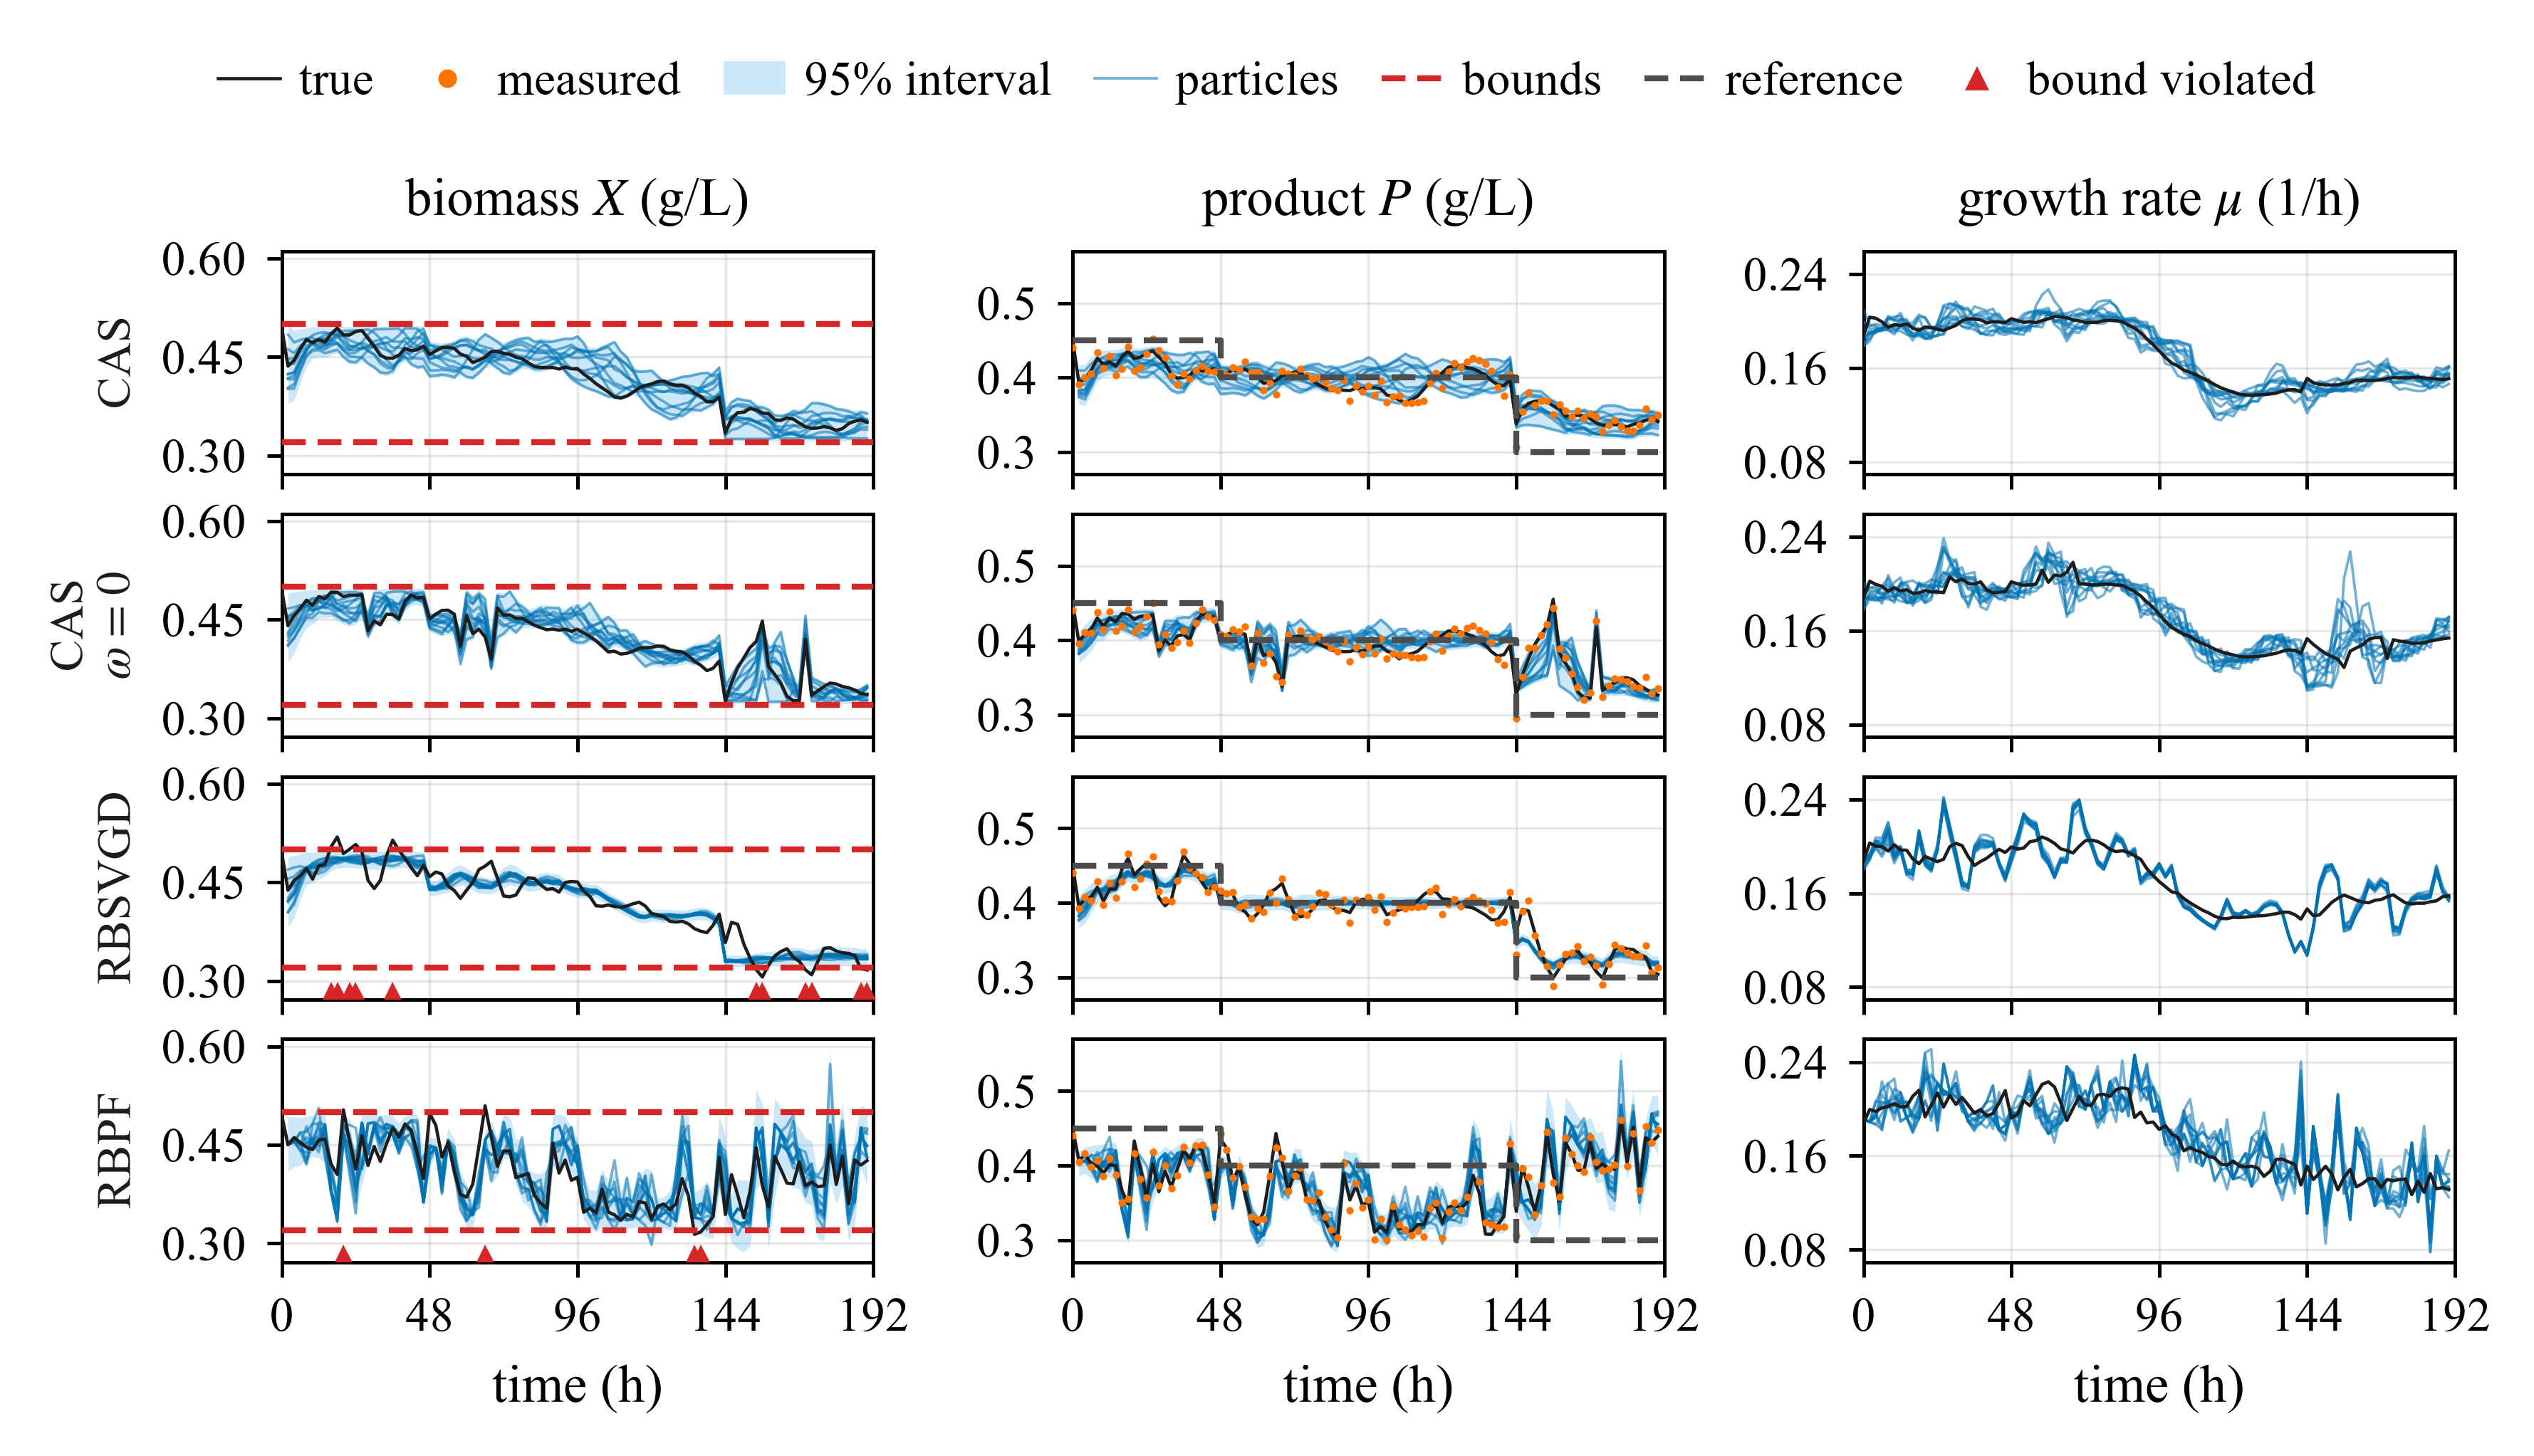

In [7]:
fig = pp.plot_bio_paper(runs, setup, methods=("ca", "ca0", "param", "rbpf"), figsize=fig_size)
pp.save_figure(fig, ROOT / "paper" / "figures" / "bio_closed_loop")
pp.save_figure(fig, ROOT / "assets" / "closed_loop", formats=("png",), dpi=200)   # README image
plt.show()

## 5. Ablation: ω = 0

The control-aware kernel without its parameter-space term, $k_\omega = k_\Phi$ (`ca0`), against the proposed
$k_\omega = k_\Phi + \omega k_\theta$ (`ca`), all other settings equal. With $\omega = 0$, particles that predict the same
outputs and margins under the shifted plan do not repel each other, so the spread of the particles in the directions that do
not affect these predictions is not maintained (paper, Section `sec:theory`). The two are compared in the figure of Section 4. One seed only: a conclusion needs the
Monte Carlo (add `"ca0"` to `methods` in `montecarlo_bioreactor.ipynb`).

In [8]:
summary.loc[["ca", "ca0"]].round(4)

,washouts,washouts low,washouts high,tracking RMSE,CRPS X,CRPS P,CRPS mu,computation ms
ca,0.0,0.0,0.0,0.0340,0.0115,0.0092,0.0034,48.0071
ca0,0.0,0.0,0.0,0.0414,0.0159,0.0135,0.0054,45.4699
